Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance Preserved:
0.5540633835693527

First Five Rows after PCA:
        PC1       PC2  Customer_Segment
0  3.316751  1.443463                 1
1  2.209465 -0.333393                 1
2  2.516740  1.031151                 1
3  3.757066  2.756372                 1
4  1.008908  0.869831                 1


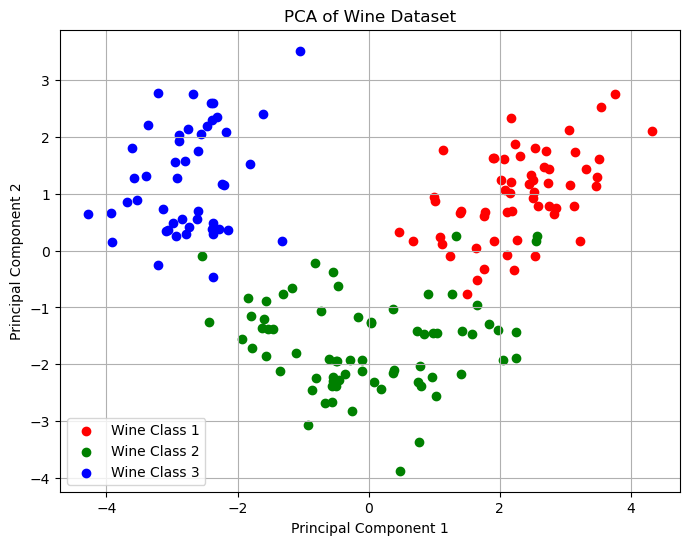

In [1]:
# Experiment 1: PCA on Wine Dataset
#Tanushri Bhise A28

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
data = pd.read_csv("Wine.csv")

# Features and target
X = data.drop("Customer_Segment", axis=1)
y = data["Customer_Segment"]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create dataframe of principal components
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Customer_Segment"] = y

# Display explained variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Preserved:")
print(sum(pca.explained_variance_ratio_))

# Display first five transformed records
print("\nFirst Five Rows after PCA:")
print(pca_df.head())

# Scatter Plot
plt.figure(figsize=(8,6))

colors = ["red", "green", "blue"]

for label, color in zip([1,2,3], colors):
    subset = pca_df[pca_df["Customer_Segment"] == label]
    plt.scatter(subset["PC1"],
                subset["PC2"],
                color=color,
                label=f"Wine Class {label}")

plt.title("PCA of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()